# 08 · Validating the synthetic order generator
**Owner:** P5 · **Question from faculty:** *what is the synthetic generator based on, and how do we know it is right?*

**Evidence the generator is built from** (details in `docs/generator.md`):

| Source | What it gives |
|---|---|
| Swiggy order report, Hotel Chinthamani, Coimbatore (464 orders, 5 Aug - 30 Sep 2026) | food menu, prices, baskets, order hours, weekend and rain effects |
| Our survey, 27 adult Coimbatore respondents | festival effect, snack/drink share and mix, weather-linked combos |
| Coimbatore outlet menus on Zomato / Swiggy / magicpin | snack and drink prices |
| Open-Meteo archive | real daily weather, 2023-09-24 to 2026-09-24 |

**Three groups of checks.**
1. *Grounding* - on the days both datasets cover, synthetic food orders look like the real Swiggy orders.
2. *Survey direction* - every effect and every combo moves the way the survey respondents say.
3. *Recovery* - fitting models to the synthetic data gives back the parameters that were planted.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plotstyle, validation as V, generator as G
plotstyle.apply()
C = plotstyle.C
OUT = ROOT / "results/validation"; OUT.mkdir(parents=True, exist_ok=True)

res = V.run_all()
summary = res["summary"]
summary.to_csv(OUT / "validation_summary.csv", index=False)
res["volume"].to_csv(OUT / "volume_effects.csv", index=False)
res["pairs"].to_csv(OUT / "pair_rules_by_regime.csv", index=False)
print(f"{summary['passed'].sum()} of {len(summary)} checks passed")

25 of 26 checks passed


## Summary of all checks

In [2]:
pd.set_option("display.max_colwidth", 80)
summary.groupby("group")["passed"].agg(["sum", "count"]).rename(columns={"sum": "passed", "count": "checks"})

,passed,checks
group,,
grounding,5,5
recovery,10,10
survey,10,11


In [3]:
summary

,group,check,expected,observed,passed,method
0,grounding,Order hour profile,same as Swiggy,"chi2=1.2, p=1.00",True,chi-square goodness of fit
1,grounding,Food basket size,same as Swiggy,"chi2=0.3, p=0.96",True,chi-square goodness of fit
2,grounding,Food order value,same distribution as Swiggy,"KS D=0.015, p=1.00",True,two-sample KS
3,grounding,Food item mix,same as Swiggy,"chi2=3.4, p=1.00",True,chi-square goodness of fit
4,grounding,Day-to-day volume pattern,positive correlation with Swiggy,"r=0.50, p=0.000",True,Pearson correlation
5,recovery,Volume effect: weekend,planted x2.47,"x2.45 [2.41, 2.49]",True,"quasi-Poisson GLM on 1,097 synthetic days, 95% CI"
6,survey,Direction: weekend,"survey says more {'less': 3, 'same': 7, 'more': 17}",x2.45,True,sign of synthetic effect vs survey majority
7,recovery,Volume effect: rain_weekday,planted x1.55,"x1.56 [1.53, 1.60]",True,"quasi-Poisson GLM on 1,097 synthetic days, 95% CI"
8,survey,Direction: rain_weekday,"survey says less {'less': 18, 'same': 5, 'more': 4}",x1.56,False,sign of synthetic effect vs survey majority
9,recovery,Volume effect: rain_weekend,planted x0.54,"x0.53 [0.52, 0.54]",True,"quasi-Poisson GLM on 1,097 synthetic days, 95% CI"


## 1. Grounding against the real Swiggy orders

Only **food** orders are compared: Chinthamani does not sell snacks or drinks, so those come from the survey instead.
The comparison window is the 51 days covered by both the Swiggy report and the weather file (5 Aug - 24 Sep 2026).

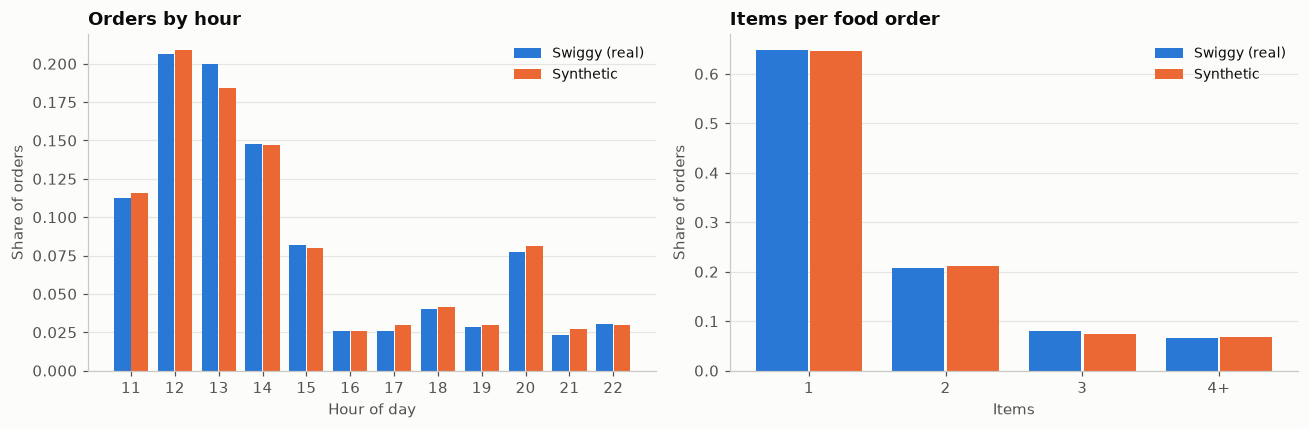

In [4]:
def paired_bars(ax, table, title, xlabel):
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["real"], 0.38, color=C["blue"], label="Swiggy (real)")
    ax.bar(x + 0.2, table["synthetic"], 0.38, color=C["orange"], label="Synthetic")
    ax.set_xticks(x, table.index.astype(str))
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Share of orders")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
paired_bars(axes[0], res["hours"], "Orders by hour", "Hour of day")
paired_bars(axes[1], res["basket_size"].sort_index(), "Items per food order", "Items")
fig.tight_layout(); fig.savefig(OUT / "fig_v1_hours_and_basket.png", dpi=150); plt.show()

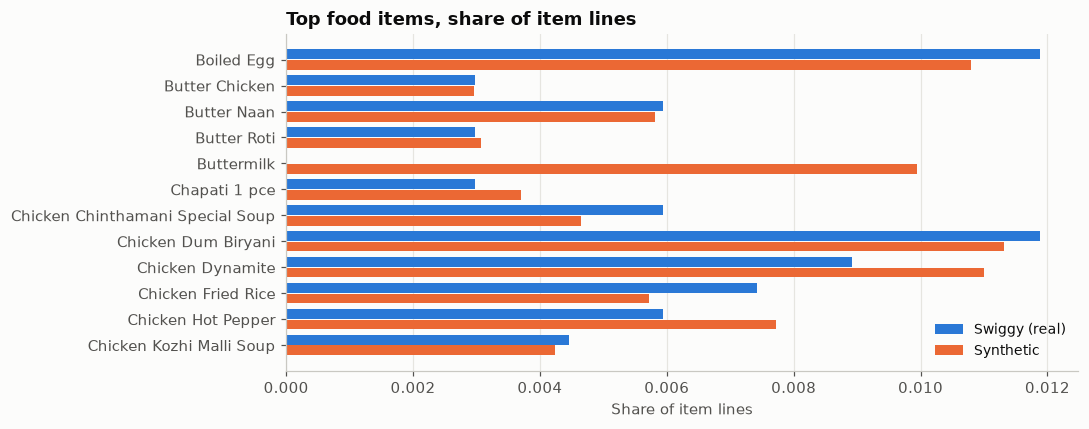

,real,synthetic
count,426.0,5976.0
mean,421.1,411.9
std,326.9,315.0
min,105.0,105.0
25%,249.0,246.0
50%,286.0,286.0
75%,518.5,498.0
max,2931.0,2979.0


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
mix = res["item_mix"].iloc[::-1]
y = np.arange(len(mix))
ax.barh(y + 0.2, mix["real"], 0.38, color=C["blue"], label="Swiggy (real)")
ax.barh(y - 0.2, mix["synthetic"], 0.38, color=C["orange"], label="Synthetic")
ax.set_yticks(y, mix.index); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Top food items, share of item lines"); ax.set_xlabel("Share of item lines"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "fig_v2_item_mix.png", dpi=150); plt.show()
res["order_value"].round(1)

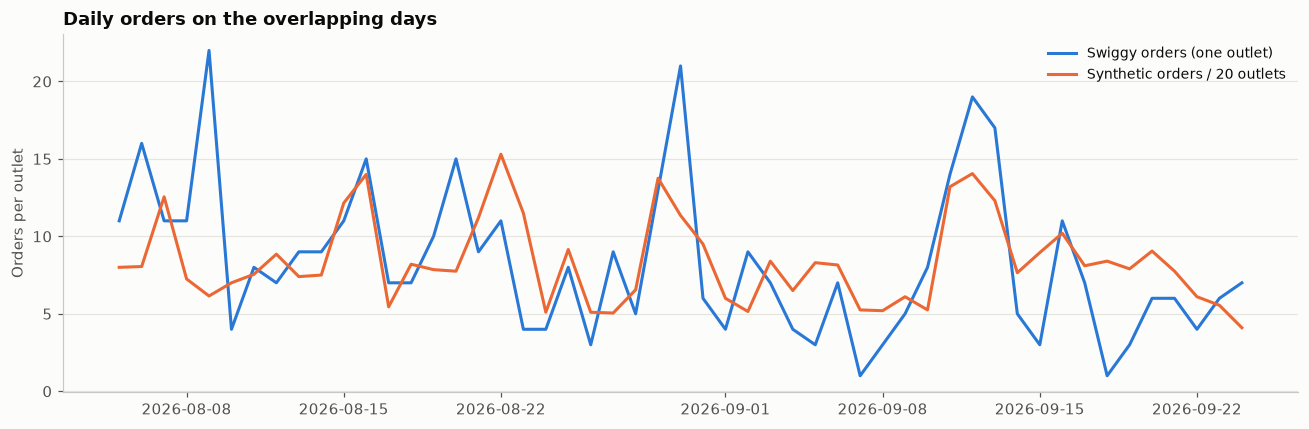

In [6]:
daily = res["daily"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(daily.index), daily["real"], color=C["blue"], label="Swiggy orders (one outlet)")
ax.plot(pd.to_datetime(daily.index), daily["synthetic_per_outlet"], color=C["orange"],
        label=f"Synthetic orders / {G.OUTLETS} outlets")
ax.set_title("Daily orders on the overlapping days"); ax.set_ylabel("Orders per outlet"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "fig_v3_daily_overlap.png", dpi=150); plt.show()

## 2-3. Volume effects: survey direction and recovery

*Planted* is the value the generator uses (from the Swiggy GLM, or the survey for festivals).
*Synthetic* is the value a fresh quasi-Poisson GLM finds in the 1,097 synthetic days.
The grey band is the 95% interval of the Swiggy estimate: how uncertain the evidence itself is.

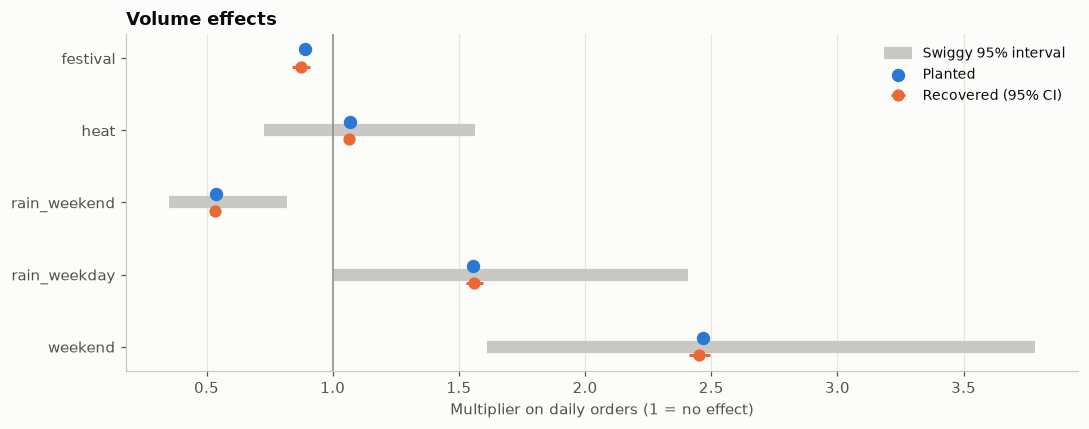

,planted,synthetic,synthetic_low,synthetic_high,swiggy_low,swiggy_high,survey_less,survey_same,survey_more
effect,,,,,,,,,
weekend,2.468,2.453,2.412,2.494,1.611,3.782,3,7,17
rain_weekday,1.555,1.562,1.527,1.597,1.004,2.408,18,5,4
rain_weekend,0.538,0.532,0.520,0.545,0.353,0.820,18,5,4
heat,1.067,1.063,1.047,1.080,0.727,1.565,5,15,7
festival,0.889,0.875,0.839,0.911,NaN,NaN,11,8,8


In [7]:
vol = res["volume"].set_index("effect")
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(vol))
ax.hlines(y, vol["swiggy_low"], vol["swiggy_high"], color=C["light"], linewidth=8, label="Swiggy 95% interval")
ax.scatter(vol["planted"], y + 0.12, color=C["blue"], s=60, zorder=3, label="Planted")
ax.errorbar(vol["synthetic"], y - 0.12, xerr=[vol["synthetic"] - vol["synthetic_low"],
            vol["synthetic_high"] - vol["synthetic"]], fmt="o", color=C["orange"], ms=7, label="Recovered (95% CI)")
ax.axvline(1, color=C["gray"], linewidth=1)
ax.set_yticks(y, vol.index); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Multiplier on daily orders (1 = no effect)"); ax.set_title("Volume effects")
ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(OUT / "fig_v4_volume_effects.png", dpi=150); plt.show()
vol.round(3)

## 2-3. Weather-linked combos

For each planted pair, the confidence P(add-on | trigger) in the synthetic orders on rainy, hot and normal days,
next to the value taken from the survey (frequency score / 4).

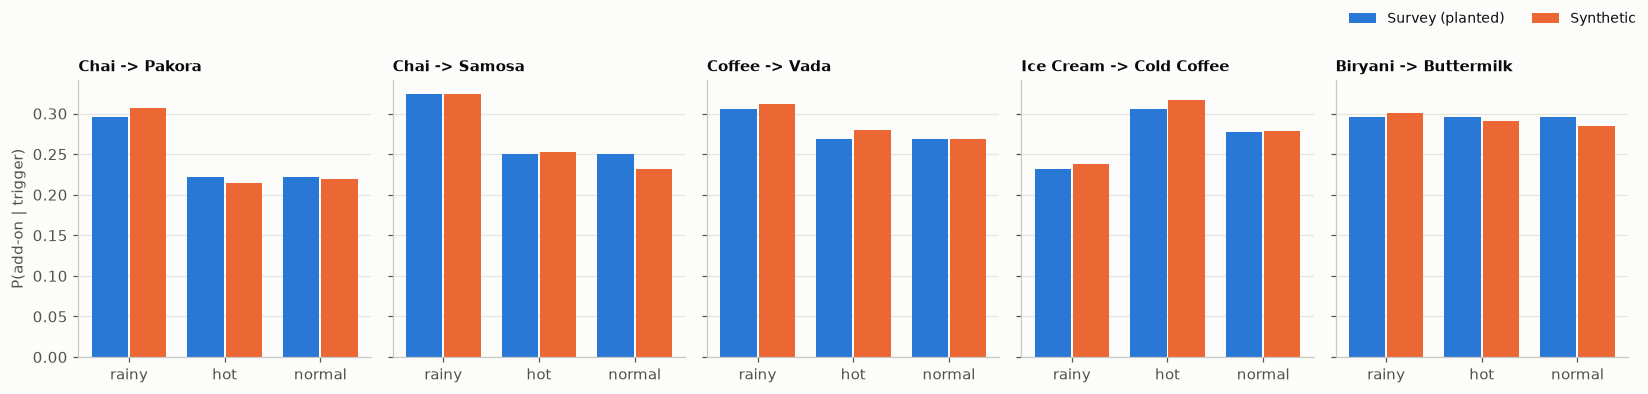

,trigger,addon,regime,planted,trigger_orders,confidence,lift
0,Chai,Pakora,rainy,0.296,4900,0.307,3.988
1,Chai,Pakora,hot,0.222,2589,0.214,5.805
2,Chai,Pakora,normal,0.222,2438,0.219,11.289
3,Chai,Samosa,rainy,0.324,4900,0.325,2.746
4,Chai,Samosa,hot,0.250,2589,0.253,6.347
5,Chai,Samosa,normal,0.250,2438,0.232,11.466
6,Coffee,Vada,rainy,0.306,5788,0.312,4.640
7,Coffee,Vada,hot,0.269,1302,0.280,7.908
8,Coffee,Vada,normal,0.269,3571,0.268,4.888
9,Ice Cream,Cold Coffee,rainy,0.231,4938,0.238,6.000


In [8]:
pairs = res["pairs"]
labels = [f"{t} -> {a}" for t, a in pairs[["trigger", "addon"]].drop_duplicates().itertuples(index=False)]
fig, axes = plt.subplots(1, len(labels), figsize=(15, 3.6), sharey=True)
for ax, (key, g) in zip(axes, pairs.groupby(["trigger", "addon"], sort=False)):
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["planted"], 0.38, color=C["blue"], label="Survey (planted)")
    ax.bar(x + 0.2, g["confidence"], 0.38, color=C["orange"], label="Synthetic")
    ax.set_xticks(x, g["regime"]); ax.set_title(f"{key[0]} -> {key[1]}", fontsize=10)
axes[0].set_ylabel("P(add-on | trigger)")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(OUT / "fig_v5_pairs.png", dpi=150); plt.show()
pairs.round(3)

## Reading the result

* **Grounding:** all five checks pass. The hour profile, basket size, order value and item mix are statistically
  indistinguishable from the real Swiggy orders, and the day-to-day volume follows the real outlet (r ~ 0.5).
  The first four are close by construction (real baskets are resampled); the check confirms nothing was lost.
* **Survey direction:** the weekend lift, heat, festival, the weather split of snack/drink orders and all five combos
  match the survey. **One check fails on purpose:** the survey majority says people order *less* when it rains,
  but the Swiggy data shows *more* orders on rainy weekdays (and fewer on rainy weekends). The generator follows the
  observed orders (team decision, option 1); the survey disagreement is reported, not hidden.
* **Recovery:** every planted volume effect and every planted pair is recovered within its confidence interval.

**Limits.** The survey is small (27 adults, mostly students). The Swiggy data is one restaurant over 57 days with no
snacks or drinks, so snack orders reuse its hour profile. Volume is that outlet scaled to 20 similar outlets.
Two snack prices (pakora, buttermilk) use the nearest real menu item as a stand-in.